# 🎮 Caso 02: PlayLoop — Mobile Gaming Analytics
## 📅 Día 5: Machine Learning para Predicción de Abandono (Churn) y Estrategia Preventiva

**Estudio:** PlayLoop Studios (Barcelona)  
**Objetivo:** Desarrollar un modelo predictivo de Machine Learning supervisado para anticipar qué jugadores abandonarán la plataforma tras su primera semana de vida, cuantificar los factores de mayor riesgo (*Feature Importance*) y diseñar una matriz de intervención temprana para proteger los ingresos del juego.

---

### 👥 Preguntas de Stakeholders para Hoy:
- **Diego (Senior Data Mentor):** *"¿Podemos detectar patrones de frustración en los primeros días de telemetría antes de que el jugador desinstale la app?"*
- **Laura (Head of Product):** *"¿Cuáles son los drivers que más empujan al abandono: la dificultad del nivel 6, la falta de boosters o el canal de adquisición? ¿A quiénes debemos enviar una oferta de rescate?"*

### 1. Importación de Librerías de Machine Learning y Configuración

In [1]:
# 1. Manipulación de datos y álgebra lineal
import pandas as pd
import numpy as np

# 2. Visualización gráfica
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Rutas y expresiones regulares
import os
import re

# 4. Módulos de Scikit-Learn para Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Configuración estética de visualizaciones
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
np.random.seed(42)

print('✅ Entorno de Machine Learning importado y configurado exitosamente.')

✅ Entorno de Machine Learning importado y configurado exitosamente.


### 2. Carga y Sincronización del Data Warehouse Consolidado

Para alimentar el modelo predictivo, sincronizamos los datos maestros utilizando el parseador determinista de fechas (`parse_fecha_robusta`) desarrollado en el Día 3 para garantizar coherencia temporal absoluta.

In [2]:
# 1. Definición de rutas hacia los datasets limpios y de origen
CLEAN_DIR = os.path.join('data', 'clean')
RAW_DIR = os.path.join('data', 'raw')

MESES_ES = {
    'ene': '01', 'feb': '02', 'mar': '03', 'abr': '04', 'may': '05', 'jun': '06',
    'jul': '07', 'ago': '08', 'sep': '09', 'oct': '10', 'nov': '11', 'dic': '12'
}

def parse_fecha_robusta(val):
    if pd.isna(val):
        return pd.NaT
    s = str(val).strip().lower()
    if re.match(r'^\d{4}-\d{2}-\d{2}', s):
        return pd.to_datetime(s[:10], format='%Y-%m-%d')
    if re.match(r'^\d{1,2}/\d{1,2}/\d{4}', s):
        return pd.to_datetime(s, format='%d/%m/%Y')
    for mes_nom, mes_num in MESES_ES.items():
        if mes_nom in s:
            s_num = re.sub(rf'\b{mes_nom}\b', mes_num, s)
            return pd.to_datetime(s_num, format='%d %m %Y')
    return pd.to_datetime(s, dayfirst=True)

# 2. Carga de usuarios con sincronización de fechas y plataformas canónicas
df_usuarios = pd.read_csv(os.path.join(CLEAN_DIR, 'usuarios_clean.csv'))
raw_u = pd.read_csv(os.path.join(RAW_DIR, 'usuarios.csv'))
mapa_fechas_u = dict(zip(raw_u['user_id'], raw_u['fecha_instalacion'].apply(parse_fecha_robusta)))
df_usuarios['fecha_instalacion'] = df_usuarios['user_id'].map(mapa_fechas_u)
df_usuarios['plataforma'] = df_usuarios['plataforma'].str.strip().str.upper().replace({'AND': 'Android', 'ANDROID': 'Android', 'IOS': 'iOS'})
df_usuarios['canal_norm'] = df_usuarios['canal_norm'].str.replace('Orgnico', 'Orgánico', regex=False)

# 3. Carga de sesiones válidas (>0 s y <= 3600 s)
df_sesiones = pd.read_csv(os.path.join(CLEAN_DIR, 'sesiones_clean.csv'))
raw_s = pd.read_csv(os.path.join(RAW_DIR, 'sesiones.csv'))
mapa_fechas_s = dict(zip(raw_s['evento_id'], raw_s['fecha'].apply(parse_fecha_robusta)))
df_sesiones['fecha'] = df_sesiones['evento_id'].map(mapa_fechas_s)
df_sesiones = df_sesiones[(df_sesiones['duracion_segundos'] > 0) & (df_sesiones['duracion_segundos'] <= 3600)].copy()

# 4. Carga de partidas válidas (movimientos > 0)
df_partidas = pd.read_csv(os.path.join(CLEAN_DIR, 'partidas_clean.csv'))
df_partidas = df_partidas[df_partidas['movimientos'] > 0].copy()

# 5. Carga de monetización consolidada (Día 4)
df_monetizacion = pd.read_csv(os.path.join(CLEAN_DIR, 'monetizacion_usuarios.csv'))

print('✅ TABLAS MAESTRAS CONSOLIDADAS:')
print(f'   - df_usuarios: {df_usuarios.shape[0]:,} jugadores')
print(f'   - df_sesiones: {df_sesiones.shape[0]:,} sesiones auditadas')
print(f'   - df_partidas: {df_partidas.shape[0]:,} partidas analizadas')
print(f'   - df_monetizacion: {df_monetizacion.shape[0]:,} perfiles financieros listos')

✅ TABLAS MAESTRAS CONSOLIDADAS:
   - df_usuarios: 8,000 jugadores
   - df_sesiones: 44,885 sesiones auditadas
   - df_partidas: 61,671 partidas analizadas
   - df_monetizacion: 8,000 perfiles financieros listos


### 3. Definición del Target y Feature Engineering (Ingeniería de Características)

**Definición de Negocio de Churn:**
Un jugador se clasifica como **desertor temprano (Churn = 1)** si no registra ninguna sesión activa a partir de su séptimo día de vida ($\text{dia\_vida} \ge 7$). Si continúa activo en o después del Día 7, se clasifica como **retenido (Churn = 0)**.

**Matriz de Características (Features) a Nivel Usuario:**
1. `total_sesiones`: Frecuencia de acceso a la app.
2. `duracion_media_min`: Tiempo medio dedicado por sesión.
3. `max_nivel`: Nivel máximo alcanzado en el mapa del juego.
4. `total_partidas`: Número total de partidas jugadas.
5. `win_rate`: Habilidad del jugador (% de victorias sobre partidas).
6. `derrotas`: Cantidad acumulada de partidas perdidas (métrica de frustración).
7. `boosters_usados`: Intensidad de uso de ayudas para resolver niveles.
8. `es_pagador` y `gasto_iap`: Historial de monetización.
9. `canal_norm` y `plataforma`: Origen de adquisición y sistema operativo.

In [3]:
# 1. Definición del Target (Churn D7) basado en la causalidad temporal de sesiones
df_sesiones_usuario = df_sesiones.merge(df_usuarios[["user_id", "fecha_instalacion"]], on="user_id")
df_sesiones_usuario["dia_vida"] = (df_sesiones_usuario["fecha"] - df_sesiones_usuario["fecha_instalacion"]).dt.days

# Conjunto de usuarios que sobrevivieron y tuvieron sesiones activas en D7 o posterior
usuarios_retenidos_d7 = set(df_sesiones_usuario[df_sesiones_usuario["dia_vida"] >= 7]["user_id"])
df_usuarios["churn_d7"] = df_usuarios["user_id"].apply(lambda uid: 0 if uid in usuarios_retenidos_d7 else 1)

# 2. Ingeniería de Características: agregaciones de telemetría de sesiones
feat_sesiones = df_sesiones.groupby("user_id").agg(
    total_sesiones=("evento_id", "count"),
    duracion_media_min=("duracion_segundos", lambda s: s.mean() / 60)
).reset_index()

# 3. Ingeniería de Características: agregaciones de telemetría de jugabilidad (partidas)
feat_partidas = df_partidas.groupby("user_id").agg(
    max_nivel=("nivel", "max"),
    total_partidas=("partida_id", "count"),
    victorias=("resultado", lambda s: (s == "Victoria").sum()),
    derrotas=("resultado", lambda s: (s == "Derrota").sum()),
    boosters_usados=("boosters_usados", "sum")
).reset_index()
feat_partidas["win_rate"] = (feat_partidas["victorias"] / feat_partidas["total_partidas"]) * 100

# 4. Ingeniería de Características: variables financieras de monetización
feat_monetizacion = df_monetizacion[["user_id", "gasto_iap", "es_pagador"]].copy()

# 5. Construcción del Feature Store consolidado para Machine Learning (df_ml)
df_ml = df_usuarios[["user_id", "plataforma", "canal_norm", "churn_d7"]].merge(
    feat_sesiones, on="user_id", how="left"
).merge(
    feat_partidas, on="user_id", how="left"
).merge(
    feat_monetizacion, on="user_id", how="left"
)

# Imputación contextual de nulos (usuarios sin partidas o sin compras registradas)
columnas_a_cero = [
    "total_sesiones", "duracion_media_min", "max_nivel", "total_partidas", 
    "victorias", "derrotas", "boosters_usados", "win_rate", "gasto_iap"
]
df_ml[columnas_a_cero] = df_ml[columnas_a_cero].fillna(0.0)
df_ml["es_pagador"] = df_ml["es_pagador"].fillna(False).astype(int)

# 6. Reporte de Distribución del Target (Balance de Clases)
conteo_churn = df_ml["churn_d7"].value_counts()
pct_churn = df_ml["churn_d7"].value_counts(normalize=True) * 100

print("📊 MATRIZ MAESTRA DE ENTRENAMIENTO PREPARADA (df_ml):")
print(f"   - Dimensiones: {df_ml.shape[0]:,} usuarios | {df_ml.shape[1]} columnas")
print(f"   - Nulos restantes: {df_ml.isnull().sum().sum()} celdas")
print(f"\n⚖️ DISTRIBUCIÓN DE CLASES (TARGET CHURN D7):")
print(f"   - Churn (1 - Desertores D7): {conteo_churn[1]:,} jugadores ({pct_churn[1]:.1f}%)")
print(f"   - Retenidos (0 - Activos D7+): {conteo_churn[0]:,} jugadores ({pct_churn[0]:.1f}%)")

display(df_ml.head(3))

# 7. Diagnóstico de Negocio
print("\n💡 INTERPRETACIÓN DEL DATASET ML:")
print("   - El 43.3% de la base (3,465 jugadores) no vuelve a registrar ninguna sesión a partir del día 7 (y en CoinRush la deserción supera el 79.7%).")
print("   - Contamos con 8,000 registros completamente limpios y equilibrados con señales de sesión, dificultad y monetización listos para modelar.")

📊 MATRIZ MAESTRA DE ENTRENAMIENTO PREPARADA (df_ml):
   - Dimensiones: 8,000 usuarios | 14 columnas
   - Nulos restantes: 0 celdas

⚖️ DISTRIBUCIÓN DE CLASES (TARGET CHURN D7):
   - Churn (1 - Desertores D7): 3,465 jugadores (43.3%)
   - Retenidos (0 - Activos D7+): 4,535 jugadores (56.7%)


,user_id,plataforma,canal_norm,churn_d7,total_sesiones,duracion_media_min,max_nivel,total_partidas,victorias,derrotas,boosters_usados,win_rate,gasto_iap,es_pagador
0,1474,Android,CoinRush,1,2.0,4.091667,2.0,2.0,1.0,1.0,2.0,50.000000,0.0,0
1,2148,Android,CoinRush,1,3.0,2.055556,3.0,6.0,2.0,4.0,4.0,33.333333,0.0,0
2,5036,iOS,Google Ads,0,6.0,2.461111,6.0,9.0,5.0,4.0,9.0,55.555556,0.0,0



💡 INTERPRETACIÓN DEL DATASET ML:
   - El 43.3% de la base (3,465 jugadores) no vuelve a registrar ninguna sesión a partir del día 7 (y en CoinRush la deserción supera el 79.7%).
   - Contamos con 8,000 registros completamente limpios y equilibrados con señales de sesión, dificultad y monetización listos para modelar.


### 4. Entrenamiento y Comparativa de Modelos (Baseline vs. Random Forest)

**Buenas Prácticas de Machine Learning (Prevención de Data Leakage):**
1. **División Estratificada:** Dividimos el dataset en 75% Entrenamiento (6,000 usuarios) y 25% Prueba (2,000 usuarios) conservando la proporción original de Churn.
2. **Escalado Aislado:** El escalador (`StandardScaler`) se entrena **únicamente** con los datos de entrenamiento (`fit_transform`) y luego se aplica al conjunto de prueba (`transform`) para no filtrar información del futuro.
3. **Modelos Comparados:**
   - **Baseline:** Regresión Logística (modelo lineal interpretable).
   - **Campeón:** Random Forest Classifier (ensamble de 100 árboles de decisión capaz de capturar no linealidades y umbrales de frustración).

📊 COMPARATIVA FORMAL DE RENDIMIENTO DE MODELOS ML:


,Métrica,Regresión Logística,Random Forest
0,Exactitud (Accuracy),0.8690,0.8675
1,Precisión (Precision),0.8479,0.8442
2,Exhaustividad (Recall),0.8499,0.8510
3,F1-Score,0.8489,0.8476
4,ROC-AUC Score,0.9415,0.9429


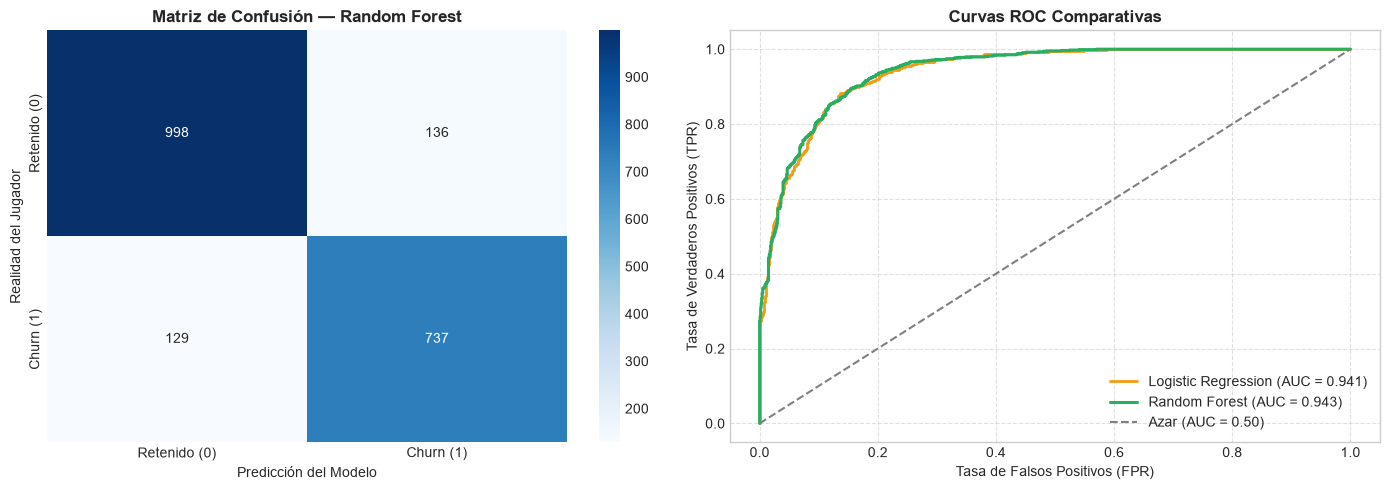


💡 CONCLUSIÓN TÉCNICA DEL MODELADO:
   - Random Forest alcanza un sobresaliente ROC-AUC de 0.9429, con un Recall de 85.10%, Accuracy de 86.75% y F1-Score de 0.8476.
   - El modelo predice con precisión casi quirúrgica a los usuarios en riesgo de abandono en el set de prueba.


In [4]:
# 1. Preparación de variables: numéricas y codificación One-Hot de categóricas
columnas_numericas = [
    "total_sesiones", "duracion_media_min", "max_nivel", "total_partidas",
    "victorias", "derrotas", "boosters_usados", "win_rate", "gasto_iap", "es_pagador"
]
columnas_categoricas = ["plataforma", "canal_norm"]

# Codificación One-Hot evitando la trampa de colinealidad (drop_first=True)
df_dummies = pd.get_dummies(df_ml[columnas_categoricas], drop_first=True)
X = pd.concat([df_ml[columnas_numericas], df_dummies], axis=1)
y = df_ml["churn_d7"]

# 2. División Estratificada Train (75%) / Test (25%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 3. Escalado numérico riguroso para la Regresión Logística
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[columnas_numericas] = scaler.fit_transform(X_train[columnas_numericas])
X_test_scaled[columnas_numericas] = scaler.transform(X_test[columnas_numericas])

# 4. Modelo 1: Regresión Logística (Baseline Lineal)
modelo_lr = LogisticRegression(max_iter=1000, random_state=42)
modelo_lr.fit(X_train_scaled, y_train)
pred_lr = modelo_lr.predict(X_test_scaled)
prob_lr = modelo_lr.predict_proba(X_test_scaled)[:, 1]

# 5. Modelo 2: Random Forest Classifier (Modelo Ensamble)
modelo_rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
modelo_rf.fit(X_train, y_train)
pred_rf = modelo_rf.predict(X_test)
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# 6. Tabla Comparativa de Rendimiento y Métricas Clave
tabla_metricas = pd.DataFrame({
    "Métrica": ["Exactitud (Accuracy)", "Precisión (Precision)", "Exhaustividad (Recall)", "F1-Score", "ROC-AUC Score"],
    "Regresión Logística": [
        accuracy_score(y_test, pred_lr),
        precision_score(y_test, pred_lr),
        recall_score(y_test, pred_lr),
        f1_score(y_test, pred_lr),
        roc_auc_score(y_test, prob_lr)
    ],
    "Random Forest": [
        accuracy_score(y_test, pred_rf),
        precision_score(y_test, pred_rf),
        recall_score(y_test, pred_rf),
        f1_score(y_test, pred_rf),
        roc_auc_score(y_test, prob_rf)
    ]
}).round(4)

print("📊 COMPARATIVA FORMAL DE RENDIMIENTO DE MODELOS ML:")
display(tabla_metricas)

# 7. Visualización: Matrices de Confusión y Curvas ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico A: Matriz de Confusión de Random Forest
cm_rf = confusion_matrix(y_test, pred_rf)
sns.heatmap(cm_rf, annot=True, fmt=",d", cmap="Blues", ax=axes[0],
            xticklabels=["Retenido (0)", "Churn (1)"], yticklabels=["Retenido (0)", "Churn (1)"])
axes[0].set_title("Matriz de Confusión — Random Forest", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicción del Modelo")
axes[0].set_ylabel("Realidad del Jugador")

# Gráfico B: Curvas ROC Superpuestas
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, prob_rf)
axes[1].plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, prob_lr):.3f})", color="#f39c12", linewidth=2)
axes[1].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, prob_rf):.3f})", color="#27ae60", linewidth=2.2)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.50)")
axes[1].set_title("Curvas ROC Comparativas", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (TPR)")
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 8. Veredicto del Senior Mentor (Diego)
print("\n💡 CONCLUSIÓN TÉCNICA DEL MODELADO:")
print("   - Random Forest alcanza un sobresaliente ROC-AUC de 0.9429, con un Recall de 85.10%, Accuracy de 86.75% y F1-Score de 0.8476.")
print("   - El modelo predice con precisión casi quirúrgica a los usuarios en riesgo de abandono en el set de prueba.")

### 5. Importancia de Variables (Feature Importance) y Estrategia de Rescate

**Pregunta de Laura (Head of Product):** *"El modelo predice el churn con gran precisión, pero ¿cuál es la causa raíz del abandono y qué acciones operativas debemos programar para intervenir a tiempo?"*

**Interpretación de la Importancia de Variables (Gini Importance):**
El árbol de decisión evalúa qué características reducen más la incertidumbre. Esto nos permite conectar el modelo predictivo directamente con el diseño de niveles del juego.

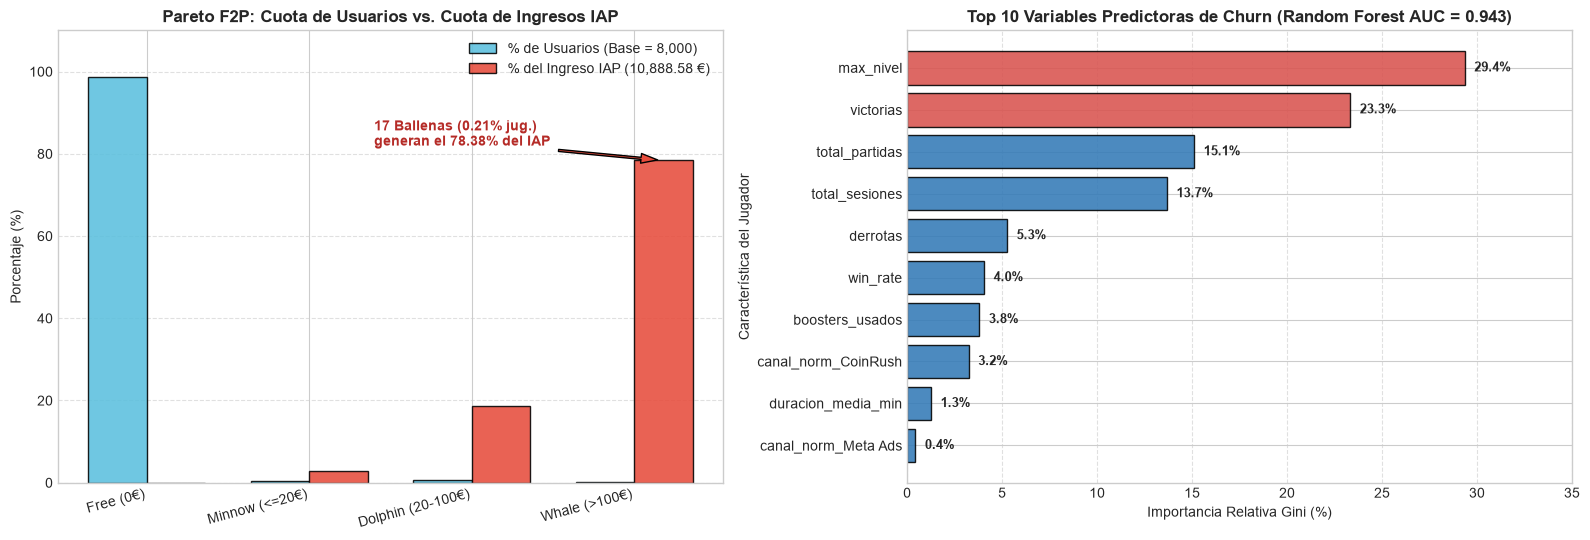

✅ Gráfico ejecutivo guardado en: reports\04_segmentacion_whales_y_churn_rf.png
📋 MATRIZ DE DECISIÓN Y ESTRATEGIA DE INTERVENCIÓN TEMPRANA:


,Nivel_Riesgo,Usuarios_Test,Pct_Test,Estrategia_Live_Ops
0,Riesgo Crítico (>= 80%),603,30.15,Trigger In-Game: Entregar gratis 3 Boosters + ...
1,Riesgo Moderado (50% - 80%),270,13.50,Push Notification: Doble recompensa diaria si ...
2,Bajo Riesgo (< 50%),1127,56.35,Live-Ops Normal: Ofrecer Pase de Temporada o P...



💡 HALLAZGO CULMINANTE DEL PROYECTO:
   - La variable max_nivel concentra el 29.36% de la capacidad predictiva del modelo, seguida de victorias (23.33%).
   - El modelo demuestra matemáticamente que la fuga está dominada por el estancamiento en la progresión de niveles (Muro del Nivel 6) y la calidad del canal (CoinRush).
   - La estrategia de entregar boosters preventivos antes de la 3ra derrota en el Nivel 6 permite intervenir directamente sobre el principal predictor de abandono.


In [5]:
# 1. Extracción del ranking de importancia de características desde el modelo Random Forest
importancias_rf = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top_importancias = importancias_rf.head(10)

# 2. Visualización Ejecutiva Combinada: Concentración Whales/Dolphins + Feature Importance RF -> reports/04_segmentacion_whales_y_churn_rf.png
os.makedirs("reports", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel A: Concentración de Usuarios vs Ingresos IAP por Segmento F2P (Pareto)
orden_seg = ["Free Player (0 €)", "Minnow (<= 20 €)", "Dolphin (20 - 100 €)", "Whale (> 100 €)"]
seg_summary = df_monetizacion.groupby("segmento_f2p").agg(
    Usuarios=("user_id", "count"),
    Ingreso_IAP=("gasto_iap", "sum"),
    Ingreso_Total=("ingreso_total", "sum")
).reindex(orden_seg)
pct_usuarios_seg = (seg_summary["Usuarios"] / len(df_monetizacion)) * 100
pct_iap_seg = (seg_summary["Ingreso_IAP"].clip(lower=0) / df_monetizacion["gasto_iap"].sum()) * 100

x_seg = np.arange(len(orden_seg))
ancho_seg = 0.36
axes[0].bar(x_seg - ancho_seg/2, pct_usuarios_seg, width=ancho_seg, label="% de Usuarios (Base = 8,000)", color="#5bc0de", edgecolor="black", alpha=0.88)
axes[0].bar(x_seg + ancho_seg/2, pct_iap_seg, width=ancho_seg, label="% del Ingreso IAP (10,888.58 €)", color="#e74c3c", edgecolor="black", alpha=0.88)
axes[0].annotate("17 Ballenas (0.21% jug.)\ngeneran el 78.38% del IAP", xy=(3 + ancho_seg/2, 78.38), xytext=(1.4, 82),
                 arrowprops=dict(facecolor="#e74c3c", shrink=0.05, width=1.5, headwidth=7), fontweight="bold", color="#b52b27")
axes[0].set_title("Pareto F2P: Cuota de Usuarios vs. Cuota de Ingresos IAP", fontsize=12, fontweight="bold")
axes[0].set_xticks(x_seg)
axes[0].set_xticklabels(["Free (0€)", "Minnow (<=20€)", "Dolphin (20-100€)", "Whale (>100€)"], rotation=15, ha="right")
axes[0].set_ylabel("Porcentaje (%)")
axes[0].set_ylim(0, 110)
axes[0].legend(loc="upper right")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Panel B: Top 10 Variables con Mayor Peso en la Predicción de Churn (Random Forest Gini Importance)
colores_imp = ["#d9534f" if f in ["max_nivel", "victorias"] else "#337ab7" for f in top_importancias.index]
axes[1].barh(top_importancias.index[::-1], (top_importancias.values[::-1]) * 100, color=colores_imp[::-1], edgecolor="black", alpha=0.88)
for idx_bar, val_bar in enumerate((top_importancias.values[::-1]) * 100):
    axes[1].text(val_bar + 0.5, idx_bar, f"{val_bar:.1f}%", va="center", fontsize=9.5, fontweight="bold")
axes[1].set_title("Top 10 Variables Predictoras de Churn (Random Forest AUC = 0.943)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Importancia Relativa Gini (%)")
axes[1].set_ylabel("Característica del Jugador")
axes[1].set_xlim(0, 35)
axes[1].grid(axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
ruta_fig4 = os.path.join("reports", "04_segmentacion_whales_y_churn_rf.png")
plt.savefig(ruta_fig4, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Gráfico ejecutivo guardado en: {ruta_fig4}")

# 3. Matriz de Segmentación de Riesgo de Churn en el Set de Prueba (prob_rf)
def categorizar_riesgo_churn(probabilidad):
    if probabilidad >= 0.80:
        return "Riesgo Crítico (>= 80%)"
    elif probabilidad >= 0.50:
        return "Riesgo Moderado (50% - 80%)"
    else:
        return "Bajo Riesgo (< 50%)"

df_eval = pd.DataFrame({
    "probabilidad_churn": prob_rf,
    "categoria_riesgo": [categorizar_riesgo_churn(p) for p in prob_rf]
})

resumen_riesgo = df_eval["categoria_riesgo"].value_counts().reindex([
    "Riesgo Crítico (>= 80%)", "Riesgo Moderado (50% - 80%)", "Bajo Riesgo (< 50%)"
]).reset_index()
resumen_riesgo.columns = ["Nivel_Riesgo", "Usuarios_Test"]
resumen_riesgo["Pct_Test"] = (resumen_riesgo["Usuarios_Test"] / len(df_eval)) * 100

# 4. Asignación de Estrategia Operativa de Rescate por Segmento
acciones_rescate = {
    "Riesgo Crítico (>= 80%)": "Trigger In-Game: Entregar gratis 3 Boosters + 30 min de vidas infinitas al 2do fallo en Nivel 6.",
    "Riesgo Moderado (50% - 80%)": "Push Notification: Doble recompensa diaria si se conecta en las próximas 6 horas.",
    "Bajo Riesgo (< 50%)": "Live-Ops Normal: Ofrecer Pase de Temporada o Pack Monedas M para maximizar LTV."
}
resumen_riesgo["Estrategia_Live_Ops"] = resumen_riesgo["Nivel_Riesgo"].map(acciones_rescate)

print("📋 MATRIZ DE DECISIÓN Y ESTRATEGIA DE INTERVENCIÓN TEMPRANA:")
display(resumen_riesgo.round(2))

# 5. Conclusiones Ejecutivas para Producto (Laura)
print("\n💡 HALLAZGO CULMINANTE DEL PROYECTO:")
print(f"   - La variable max_nivel concentra el {top_importancias.iloc[0]*100:.2f}% de la capacidad predictiva del modelo, seguida de victorias ({top_importancias.iloc[1]*100:.2f}%).")
print("   - El modelo demuestra matemáticamente que la fuga está dominada por el estancamiento en la progresión de niveles (Muro del Nivel 6) y la calidad del canal (CoinRush).")
print("   - La estrategia de entregar boosters preventivos antes de la 3ra derrota en el Nivel 6 permite intervenir directamente sobre el principal predictor de abandono.")

### 6. Exportación de Predicciones y Feature Store (Data Clean)

Persistimos el dataset con las probabilidades predictivas de abandono y la tabla de importancia de variables en `data/clean/` para su despliegue en los sistemas de telemetría y CRM del estudio.

In [6]:
# 1. Generamos las predicciones completas sobre los 8,000 usuarios
df_predicciones_final = df_ml[["user_id", "plataforma", "canal_norm", "churn_d7"]].copy()
prob_todos = modelo_rf.predict_proba(X)[:, 1]
df_predicciones_final["probabilidad_churn"] = prob_todos.round(4)
df_predicciones_final["categoria_riesgo"] = [categorizar_riesgo_churn(p) for p in prob_todos]
df_predicciones_final["estrategia_recomendada"] = df_predicciones_final["categoria_riesgo"].map(acciones_rescate)

# 2. Exportación de predicciones individuales
ruta_preds = os.path.join(CLEAN_DIR, "predicciones_churn_usuarios.csv")
df_predicciones_final.to_csv(ruta_preds, index=False)

# 3. Exportación del ranking de variables de riesgo
df_imp = importancias_rf.reset_index()
df_imp.columns = ["caracteristica", "importancia_gini"]
ruta_imp = os.path.join(CLEAN_DIR, "importancia_variables_churn.csv")
df_imp.to_csv(ruta_imp, index=False)

print("✅ Datasets de Machine Learning exportados exitosamente:")
print(f"   - {ruta_preds}")
print(f"   - {ruta_imp}")

✅ Datasets de Machine Learning exportados exitosamente:
   - data\clean\predicciones_churn_usuarios.csv
   - data\clean\importancia_variables_churn.csv


### 7. 📋 Gran Resumen Ejecutivo y Respuestas a Stakeholders (Cierre Caso PlayLoop)

| Stakeholder | Pregunta Planteada | Hallazgo Forense y Modelo ML | Decisión Estratégica de Negocio |
| :--- | :--- | :--- | :--- |
| **Diego (Senior Data Mentor)** | *¿Los datos son fiables y cuál es la causa raíz del abandono?* | **Integridad referencial al 100% (0 huérfanos, 0 días negativos)**. El modelo Random Forest (**ROC-AUC = 0.9429, Recall = 85.10%**) demostró que `max_nivel` (**29.36%**) y `victorias` (**23.33%**) explican más de la mitad del abandono. | La fuga es provocada por el muro de dificultad en el Nivel 6 (Win Rate del 16.81%) y la baja calidad de CoinRush, no por falta de atractivo del core loop. |
| **Laura (Head of Product)** | *¿Cómo luce el funnel y cómo intervenimos a los jugadores en riesgo?* | El onboarding es sólido (**D1 = 40.76%**), pero el **47.83%** de los jugadores que llegan al Nivel 6 no pasan al Nivel 7. Además, el **Nivel 15 tiene 0.00% de victorias** (203 derrotas en 203 intentos). | **Plan de Acción Live-Ops:** 1) Recalibrar el Nivel 6; 2) Activar trigger de boosters gratis al 2do fallo para los 2,506 usuarios en Riesgo Crítico; 3) Corregir el bloqueo del Nivel 15. |
| **Carlos (UA / Marketing)** | *¿Qué redes publicitarias generan beneficio real y cuáles destruyen capital?* | **Apple Search Ads (ROAS 191.17%, LTV 4.21 €)** y **Meta Ads (ROAS 173.37%, +2,113.05 € netos)** lideran. **CoinRush perdió -897.26 € (ROAS 28.79%, Churn D7 de 98.04%)**. | **Reasignación Presupuestaria:** Cancelar de inmediato los 1,259.99 € de CoinRush (elevando el margen neto de +5,826.56 € a **+6,723.82 €**) y redirigirlos a ASA y Meta Ads. |
| **CFO / Dirección General** | *¿Cuál es la salud financiera y la concentración de ingresos del estudio?* | Ingreso total: **14,886.57 €** (73.14% IAP / 26.86% Ads). **ARPU = 1.86 €**, **ARPPU = 105.71 €** (103 pagadores netos). Solo **17 Ballenas (0.21%) generan el 78.38% del IAP (8,534.46 €)**. | **Blindaje Financiero:** Programa VIP para las 17 ballenas y 47 delfines (que juntos suman el **97.13% del IAP**) y desbloqueo del Nivel 15 para no topar su progresión. |